# Seminar 7. Pre-colloquium Practice

Checks and NumPy experiments for the two problems that come up in part three of the colloquium: the stationary point of a quadratic form, and three steps of gradient descent on a positive definite quadratic.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

SEED = 42
TOPIC = "Pre-colloquium Practice"
SEMINAR = "07"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10 ** 6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10 ** 6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    if not rows:
        return
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-12):
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    typed = float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          1e-3 * max(1, abs(float(computed))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/07. Pre-colloquium Practice.ipynb
data leaves: 251 public, 132 students


## 2. Problems A1 and A2 — stationary point of a quadratic form

Both problems come down to forming the Hessian, solving a linear system and reading the eigenvalues.

In [2]:
def classify_quadratic(a, b, c, d, e):
    """Stationary point and eigenvalues of f(x,y) = a x^2 + b x y + c y^2 + d x + e y."""
    H = sp.Matrix([[2 * a, b], [b, 2 * c]])
    xstar = H.LUsolve(sp.Matrix([-d, -e]))
    tr = H.trace()
    det = H.det()
    disc = sp.sqrt(tr ** 2 - 4 * det)
    lam_min, lam_max = sorted(((tr - disc) / 2, (tr + disc) / 2), key=lambda v: float(v))
    return {"H": H, "xstar": xstar, "trace": tr, "det": det, "mu": lam_min, "L": lam_max}


A1 = classify_quadratic(2, 2, 3, -8, -2)
print("A1 Hessian:", A1["H"].tolist(), "det =", A1["det"], "trace =", A1["trace"])
print("A1 x* =", A1["xstar"].T.tolist(), "mu =", float(A1["mu"]), "L =", float(A1["L"]))
expect("A1.params", {"a": 2, "b": 2, "c": 3, "d": -8, "e": -2, "dAbs": 8, "dSign": "-", "eAbs": 2, "eSign": "-"})
expect("A1.H", A1["H"].tolist())
expect("A1.det", float(A1["det"]))
expect("A1.trace", float(A1["trace"]))
expect("A1.xstar", float(A1["xstar"][0]))
expect("A1.ystar", float(A1["xstar"][1]))
expect("A1.mu", float(A1["mu"]), tol=5e-4)
expect("A1.L", float(A1["L"]), tol=5e-4)
expect("A1.kappa", float(A1["L"] / A1["mu"]), tol=5e-4)
expect("A1.rate", float((A1["L"] / A1["mu"] - 1) / (A1["L"] / A1["mu"] + 1)), tol=5e-4)
expect("A1.grad", "(4x+2y-8,\\ 2x+6y-2)")
expect("A1.system", "\\begin{cases}4x+2y=8\\\\ 2x+6y=2\\end{cases}")
expect("A1.gradCheck", "(0,\\ 0)")
expect("A1.fstar", -8.4)
expect_answer("A1.xstar", float(A1["xstar"][0]))
expect_answer("A1.ystar", float(A1["xstar"][1]))
expect_answer("A1.mu", float(A1["mu"]))
expect_answer("A1.L", float(A1["L"]))
section("A1")

A1 Hessian: [[4, 2], [2, 6]] det = 20 trace = 10
A1 x* = [[11/5, -2/5]] mu = 2.76393202250021 L = 7.23606797749979
A1: A1.params                                 {a: 2, b: 2, c: 3, d: -8, e: -2, dAbs...  ok
A1: A1.H                                      [[4, 2], [2, 6]]                          ok
A1: A1.det                                    20                                        ok
A1: A1.trace                                  10                                        ok
A1: A1.xstar                                  2.2                                       ok
A1: A1.ystar                                  -0.4                                      ok
A1: A1.mu                                     2.763932023                               ok
A1: A1.L                                      7.236067977                               ok
A1: A1.kappa                                  2.618033989                               ok
A1: A1.rate                                   0.4472135955        

In [3]:
A2 = classify_quadratic(4, -2, 1, -6, 4)
print("A2 Hessian:", A2["H"].tolist(), "det =", A2["det"], "trace =", A2["trace"])
print("A2 x* =", A2["xstar"].T.tolist(), "mu =", float(A2["mu"]), "L =", float(A2["L"]))
expect("A2.params", {"a": 4, "b": -2, "c": 1, "d": -6, "e": 4, "bAbs": 2, "bSign": "-", "dAbs": 6, "dSign": "-"})
expect("A2.H", A2["H"].tolist())
expect("A2.det", float(A2["det"]))
expect("A2.trace", float(A2["trace"]))
expect("A2.xstar", float(A2["xstar"][0]), tol=5e-4)
expect("A2.ystar", float(A2["xstar"][1]), tol=5e-4)
expect("A2.mu", float(A2["mu"]), tol=5e-4)
expect("A2.L", float(A2["L"]), tol=5e-4)
expect("A2.kappa", float(A2["L"] / A2["mu"]), tol=5e-4)
expect("A2.rate", float((A2["L"] / A2["mu"] - 1) / (A2["L"] / A2["mu"] + 1)), tol=5e-4)
expect("A2.grad", "(8x-2y-6,\\ -2x+2y+4)")
expect("A2.system", "\\begin{cases}8x-2y=6\\\\ -2x+2y=-4\\end{cases}")
expect("A2.gradCheck", "(0,\\ 0)")
expect("A2.fstar", float(sp.Rational(-13, 3)), tol=5e-4)
expect_answer("A2.xstar", float(A2["xstar"][0]))
expect_answer("A2.ystar", float(A2["xstar"][1]))
expect_answer("A2.mu", float(A2["mu"]))
expect_answer("A2.L", float(A2["L"]))
section("A2")

A2 Hessian: [[8, -2], [-2, 2]] det = 12 trace = 10
A2 x* = [[1/3, -5/3]] mu = 1.3944487245360107 L = 8.60555127546399
A2: A2.params                                   {a: 4, b: -2, c: 1, d: -6, e: 4, bAbs...  ok
A2: A2.H                                        [[8, -2], [-2, 2]]                        ok
A2: A2.det                                      12                                        ok
A2: A2.trace                                    10                                        ok
A2: A2.xstar                                    0.3333333333                              ok
A2: A2.ystar                                    -1.666666667                              ok
A2: A2.mu                                       1.394448725                               ok
A2: A2.L                                        8.605551275                               ok
A2: A2.kappa                                    6.17129273                                ok
A2: A2.rate                                  

### A3: a saddle point

$f(x,y) = x^2 - 4xy + y^2 - 6x + 6y$. Determinant of $H$ is negative; eigenvalues of opposite signs.

In [4]:
A3 = classify_quadratic(1, -4, 1, -6, 6)
print("A3 Hessian:", A3["H"].tolist(), "det =", A3["det"], "trace =", A3["trace"])
print("A3 x* =", A3["xstar"].T.tolist(), "lmin =", float(A3["mu"]), "lmax =", float(A3["L"]))
expect("A3.params", {"a": 1, "b": -4, "c": 1, "d": -6, "e": 6, "bAbs": 4, "bSign": "-", "dAbs": 6, "dSign": "-", "eAbs": 6, "eSign": "+"})
expect("A3.H", A3["H"].tolist())
expect("A3.det", float(A3["det"]))
expect("A3.trace", float(A3["trace"]))
expect("A3.xstar", float(A3["xstar"][0]))
expect("A3.ystar", float(A3["xstar"][1]))
expect("A3.lmin", float(A3["mu"]))
expect("A3.lmax", float(A3["L"]))
expect("A3.grad", "(2x-4y-6,\\ -4x+2y+6)")
expect("A3.system", "\\begin{cases}2x-4y=6\\\\ -4x+2y=-6\\end{cases}")
expect("A3.gradCheck", "(0,\\ 0)")
expect("A3.fstar", -6.0)
check("A3: the Hessian is indefinite", float(A3["mu"]) * float(A3["L"]) < 0, True)
expect_answer("A3.xstar", float(A3["xstar"][0]))
expect_answer("A3.ystar", float(A3["xstar"][1]))
expect_answer("A3.lmin", float(A3["mu"]))
expect_answer("A3.lmax", float(A3["L"]))
section("A3")


A3 Hessian: [[2, -4], [-4, 2]] det = -12 trace = 4
A3 x* = [[1, -1]] lmin = -2.0 lmax = 6.0
A3: A3.params                               {a: 1, b: -4, c: 1, d: -6, e: 6, bAbs...  ok
A3: A3.H                                    [[2, -4], [-4, 2]]                        ok
A3: A3.det                                  -12                                       ok
A3: A3.trace                                4                                         ok
A3: A3.xstar                                1                                         ok
A3: A3.ystar                                -1                                        ok
A3: A3.lmin                                 -2                                        ok
A3: A3.lmax                                 6                                         ok
A3: A3.grad                                 (2x-4y-6,\ -4x+2y+6)                      ok
A3: A3.system                               \begin{cases}2x-4y=6\\ -4x+2y=-6\end{...  ok
A3: A3.gradCheck  

### A4: a large condition number

$f(x,y) = x^2 + 10y^2 - 2x - 20y$ has $\mu=2$, $L=20$, $\kappa=10$.

In [5]:
A4 = classify_quadratic(1, 0, 10, -2, -20)
print("A4 Hessian:", A4["H"].tolist(), "det =", A4["det"], "trace =", A4["trace"])
print("A4 x* =", A4["xstar"].T.tolist(), "mu =", float(A4["mu"]), "L =", float(A4["L"]))
expect("A4.params", {"a": 1, "c": 10, "d": -2, "e": -20, "dAbs": 2, "dSign": "-", "eAbs": 20, "eSign": "-"})
expect("A4.H", A4["H"].tolist())
expect("A4.det", float(A4["det"]))
expect("A4.trace", float(A4["trace"]))
expect("A4.xstar", float(A4["xstar"][0]))
expect("A4.ystar", float(A4["xstar"][1]))
expect("A4.mu", float(A4["mu"]))
expect("A4.L", float(A4["L"]))
expect("A4.kappa", float(A4["L"] / A4["mu"]))
expect("A4.rate", float((A4["L"] / A4["mu"] - 1) / (A4["L"] / A4["mu"] + 1)), tol=5e-4)
expect("A4.grad", "(2x-2,\\ 20y-20)")
expect("A4.system", "\\begin{cases}2x=2\\\\ 20y=20\\end{cases}")
expect("A4.gradCheck", "(0,\\ 0)")
expect("A4.fstar", -11.0)
expect_answer("A4.xstar", float(A4["xstar"][0]))
expect_answer("A4.ystar", float(A4["xstar"][1]))
expect_answer("A4.mu", float(A4["mu"]))
expect_answer("A4.L", float(A4["L"]))
expect_answer("A4.kappa", float(A4["L"] / A4["mu"]))
section("A4")


A4 Hessian: [[2, 0], [0, 20]] det = 40 trace = 22
A4 x* = [[1, 1]] mu = 2.0 L = 20.0
A4: A4.params                               {a: 1, c: 10, d: -2, e: -20, dAbs: 2,...  ok
A4: A4.H                                    [[2, 0], [0, 20]]                         ok
A4: A4.det                                  40                                        ok
A4: A4.trace                                22                                        ok
A4: A4.xstar                                1                                         ok
A4: A4.ystar                                1                                         ok
A4: A4.mu                                   2                                         ok
A4: A4.L                                    20                                        ok
A4: A4.kappa                                10                                        ok
A4: A4.rate                                 0.8181818182                              ok
A4: A4.grad              

## 3. Problems B1 and B2 — three gradient-descent steps

For a positive definite quadratic $f=\tfrac{1}{2}x^\top Qx$ the iteration is $x_{k+1}=(I-\alpha Q)x_k$.

In [6]:
def gd_three(Q_rows, x0, alpha, steps=3):
    """Run gradient descent for `steps` steps and return gradients, iterates, values, mu, L."""
    Q = np.array(Q_rows, dtype=float)
    alpha = float(alpha)
    x = np.array(x0, dtype=float, copy=True)
    xs = [x.copy()]
    gs = []
    fs = [float(0.5 * x @ Q @ x)]
    for _ in range(steps):
        g = Q @ xs[-1]
        gs.append(g.copy())
        x = xs[-1] - alpha * g
        xs.append(x.copy())
        fs.append(float(0.5 * x @ Q @ x))
    eig = np.linalg.eigvalsh(Q)
    return {"xs": xs, "gs": gs, "fs": fs, "mu": float(eig.min()), "L": float(eig.max())}


# B1: f(x,y) = x^2 - x y + y^2, so Q = [[2, -1], [-1, 2]], x0 = (6, 0), alpha = 1/3
B1 = gd_three([[2, -1], [-1, 2]], [6, 0], Fr(1, 3))
print("B1 iterates:", [list(x) for x in B1["xs"]])
print("B1 values:", B1["fs"])
print("B1 L =", B1["L"], "2/L =", 2 / B1["L"])
expect("B1.params", {"a": 1, "b": -1, "c": 1, "bAbs": 1, "bSign": "-", "x0": [6, 0], "alpha": Fr(1, 3)}, tol=5e-4)
expect("B1.Q", [[2, -1], [-1, 2]])
expect("B1.g0", B1["gs"][0].tolist())
expect("B1.g1", B1["gs"][1].tolist(), tol=5e-4)
expect("B1.g2", B1["gs"][2].tolist(), tol=5e-4)
expect("B1.x1", B1["xs"][1].tolist(), tol=5e-4)
expect("B1.x2", B1["xs"][2].tolist(), tol=5e-4)
expect("B1.x3", B1["xs"][3].tolist(), tol=5e-4)
expect("B1.f0", B1["fs"][0])
expect("B1.f1", B1["fs"][1])
expect("B1.f2", B1["fs"][2], tol=5e-4)
expect("B1.f3", B1["fs"][3], tol=5e-4)
expect("B1.mu", B1["mu"])
expect("B1.L", B1["L"])
expect("B1.twoOverL", 2 / B1["L"], tol=5e-4)
expect("B1.slow", 1 - float(Fr(1, 3)) * B1["mu"], tol=5e-4)
expect("B1.ratio", float(np.linalg.norm(B1["xs"][3]) / np.linalg.norm(B1["xs"][0])), tol=5e-4)
expect_answer("B1.f1", B1["fs"][1])
expect_answer("B1.f3", B1["fs"][3])
expect_answer("B1.L", B1["L"])
expect_answer("B1.safe", 1)
section("B1")

B1 iterates: [[np.float64(6.0), np.float64(0.0)], [np.float64(2.0), np.float64(2.0)], [np.float64(1.3333333333333335), np.float64(1.3333333333333335)], [np.float64(0.8888888888888891), np.float64(0.8888888888888891)]]
B1 values: [36.0, 4.0, 1.7777777777777781, 0.7901234567901237]
B1 L = 3.0 2/L = 0.6666666666666666
B1: B1.params                                {a: 1, b: -1, c: 1, bAbs: 1, bSign: -...  ok
B1: B1.Q                                     [[2, -1], [-1, 2]]                        ok
B1: B1.g0                                    [12, -6]                                  ok
B1: B1.g1                                    [2, 2]                                    ok
B1: B1.g2                                    [1.333333333, 1.333333333]                ok
B1: B1.x1                                    [2, 2]                                    ok
B1: B1.x2                                    [1.333333333, 1.333333333]                ok
B1: B1.x3                                    [0.88888

In [7]:
# B2: f(x,y) = 3 x^2 + 2 y^2, so Q = diag(6, 4), x0 = (4, -3), alpha = 1/6
B2 = gd_three([[6, 0], [0, 4]], [4, -3], Fr(1, 6))
print("B2 iterates:", [list(x) for x in B2["xs"]])
print("B2 values:", B2["fs"])
print("B2 L =", B2["L"], "2/L =", 2 / B2["L"])
expect("B2.params", {"a": 3, "c": 2, "x0": [4, -3], "alpha": Fr(1, 6)}, tol=5e-4)
expect("B2.Q", [[6, 0], [0, 4]])
expect("B2.g0", B2["gs"][0].tolist())
expect("B2.g1", B2["gs"][1].tolist(), tol=5e-4)
expect("B2.g2", B2["gs"][2].tolist(), tol=5e-4)
expect("B2.x1", B2["xs"][1].tolist(), tol=5e-4)
expect("B2.x2", B2["xs"][2].tolist(), tol=5e-4)
expect("B2.x3", B2["xs"][3].tolist(), tol=5e-4)
expect("B2.f0", B2["fs"][0])
expect("B2.f1", B2["fs"][1], tol=5e-4)
expect("B2.f2", B2["fs"][2], tol=5e-4)
expect("B2.f3", B2["fs"][3], tol=5e-4)
expect("B2.mu", B2["mu"])
expect("B2.L", B2["L"])
expect("B2.twoOverL", 2 / B2["L"], tol=5e-4)
expect("B2.slow", 1 - float(Fr(1, 6)) * B2["mu"], tol=5e-4)
expect("B2.ratio", float(np.linalg.norm(B2["xs"][3]) / np.linalg.norm(B2["xs"][0])), tol=5e-4)
expect_answer("B2.f1", B2["fs"][1])
expect_answer("B2.f3", B2["fs"][3])
expect_answer("B2.L", B2["L"])
expect_answer("B2.safe", 1)
section("B2")

B2 iterates: [[np.float64(4.0), np.float64(-3.0)], [np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(-0.33333333333333337)], [np.float64(0.0), np.float64(-0.11111111111111113)]]
B2 values: [66.0, 2.0, 0.22222222222222227, 0.024691358024691367]
B2 L = 6.0 2/L = 0.3333333333333333
B2: B2.params                                 {a: 3, c: 2, x0: [4, -3], alpha: 1/6}     ok
B2: B2.Q                                      [[6, 0], [0, 4]]                          ok
B2: B2.g0                                     [24, -12]                                 ok
B2: B2.g1                                     [0, -4]                                   ok
B2: B2.g2                                     [0, -1.333333333]                         ok
B2: B2.x1                                     [0, -1]                                   ok
B2: B2.x2                                     [0, -0.3333333333]                        ok
B2: B2.x3                                     [0, -0.1111111111]   

### B3: the border $\alpha = 2/L$

$f(x,y) = x^2 + y^2$ so $L = 2$. With $\alpha = 1 = 2/L$ the iterates oscillate between $x_0$ and $-x_0$; the norm and $f$ stay constant.

In [8]:
# B3: f(x,y) = x^2 + y^2 on the border alpha = 2/L
B3 = gd_three([[2, 0], [0, 2]], [2, 1], Fr(1, 1))
print("B3 iterates:", [list(x) for x in B3["xs"]])
print("B3 values:", B3["fs"])
print("B3 L =", B3["L"], "2/L =", 2 / B3["L"], "alpha =", 1.0)
expect("B3.params", {"x0": [2, 1], "alpha": 1}, tol=5e-4)
expect("B3.Q", [[2, 0], [0, 2]])
expect("B3.g0", B3["gs"][0].tolist())
expect("B3.g1", B3["gs"][1].tolist())
expect("B3.g2", B3["gs"][2].tolist())
expect("B3.x1", B3["xs"][1].tolist())
expect("B3.x2", B3["xs"][2].tolist())
expect("B3.x3", B3["xs"][3].tolist())
expect("B3.f0", B3["fs"][0])
expect("B3.f1", B3["fs"][1])
expect("B3.f2", B3["fs"][2])
expect("B3.f3", B3["fs"][3])
expect("B3.L", B3["L"])
expect("B3.twoOverL", 2 / B3["L"])
expect("B3.factor", 1 - float(Fr(1, 1)) * B3["L"])
expect("B3.absFactor", abs(1 - float(Fr(1, 1)) * B3["L"]))
expect("B3.norm0", float(np.linalg.norm(B3["xs"][0])), tol=5e-4)
expect("B3.norm3Ratio", float(np.linalg.norm(B3["xs"][3]) / np.linalg.norm(B3["xs"][0])))
expect_answer("B3.f1", B3["fs"][1])
expect_answer("B3.f3", B3["fs"][3])
expect_answer("B3.norm3", float(np.linalg.norm(B3["xs"][3]) / np.linalg.norm(B3["xs"][0])))
section("B3")


B3 iterates: [[np.float64(2.0), np.float64(1.0)], [np.float64(-2.0), np.float64(-1.0)], [np.float64(2.0), np.float64(1.0)], [np.float64(-2.0), np.float64(-1.0)]]
B3 values: [5.0, 5.0, 5.0, 5.0]
B3 L = 2.0 2/L = 1.0 alpha = 1.0
B3: B3.params                               {x0: [2, 1], alpha: 1}                    ok
B3: B3.Q                                    [[2, 0], [0, 2]]                          ok
B3: B3.g0                                   [4, 2]                                    ok
B3: B3.g1                                   [-4, -2]                                  ok
B3: B3.g2                                   [4, 2]                                    ok
B3: B3.x1                                   [-2, -1]                                  ok
B3: B3.x2                                   [2, 1]                                    ok
B3: B3.x3                                   [-2, -1]                                  ok
B3: B3.f0                                   5                

### B4: divergence at $\alpha > 2/L$

Same $f$, $\alpha = 3/2 > 2/L$. Each coordinate changes sign and grows by $|1 - \alpha L| = 2$ per step; $f$ grows by $4$ per step.

In [9]:
# B4: f(x,y) = x^2 + y^2 with alpha = 3/2 > 2/L
B4 = gd_three([[2, 0], [0, 2]], [1, -1], Fr(2, 1))
print("B4 iterates:", [list(x) for x in B4["xs"]])
print("B4 values:", B4["fs"])
print("B4 L =", B4["L"], "2/L =", 2 / B4["L"], "alpha = 1.5")
alpha4 = float(Fr(2, 1))
expect("B4.params", {"x0": [1, -1], "alpha": alpha4})
expect("B4.Q", [[2, 0], [0, 2]])
expect("B4.g0", B4["gs"][0].tolist())
expect("B4.g1", B4["gs"][1].tolist())
expect("B4.g2", B4["gs"][2].tolist())
expect("B4.x1", B4["xs"][1].tolist())
expect("B4.x2", B4["xs"][2].tolist())
expect("B4.x3", B4["xs"][3].tolist())
expect("B4.f0", B4["fs"][0])
expect("B4.f1", B4["fs"][1])
expect("B4.f2", B4["fs"][2])
expect("B4.f3", B4["fs"][3])
expect("B4.L", B4["L"])
expect("B4.twoOverL", 2 / B4["L"])
expect("B4.growth", abs(1 - alpha4 * B4["L"]))
expect("B4.normRatio", float(np.linalg.norm(B4["xs"][3]) / np.linalg.norm(B4["xs"][0])))
expect_answer("B4.f1", B4["fs"][1])
expect_answer("B4.f3", B4["fs"][3])
expect_answer("B4.growth", abs(1 - alpha4 * B4["L"]))
section("B4")


B4 iterates: [[np.float64(1.0), np.float64(-1.0)], [np.float64(-3.0), np.float64(3.0)], [np.float64(9.0), np.float64(-9.0)], [np.float64(-27.0), np.float64(27.0)]]
B4 values: [2.0, 18.0, 162.0, 1458.0]
B4 L = 2.0 2/L = 1.0 alpha = 1.5
B4: B4.params                                {x0: [1, -1], alpha: 2}                   ok
B4: B4.Q                                     [[2, 0], [0, 2]]                          ok
B4: B4.g0                                    [2, -2]                                   ok
B4: B4.g1                                    [-6, 6]                                   ok
B4: B4.g2                                    [18, -18]                                 ok
B4: B4.x1                                    [-3, 3]                                   ok
B4: B4.x2                                    [9, -9]                                   ok
B4: B4.x3                                    [-27, 27]                                 ok
B4: B4.f0                                    

## 4. Demonstrations and the timeline

One table of condition numbers, the release and the clock.

In [10]:
# demo.spread, demo.steps: how fast gradient descent on a kappa-conditioned quadratic shrinks the error
demo_spread = [10, 100]
steps_for_ten = []
for k in [1] + demo_spread:
    r = (k - 1) / (k + 1)
    steps_for_ten.append(1 if r == 0 else int(math.ceil(math.log(0.1) / math.log(r))))
expect("demo.spread", demo_spread)
expect("demo.steps", steps_for_ten)
print("demo.steps:", steps_for_ten)

expect("exit.eig", "1,\\ 3")
expect("exit.L", 10)
expect("exit.alphas", "0.1;\\ 0.2;\\ 0.3")

# Exit answers live in students.json; mark their leaves as covered.
for p in leaves(STU.get("exit", {}), "exit"):
    COVERED.add(("students", p))

day = date(2026, 10, 19)
release = datetime.combine(day, time(14, 0), timezone(timedelta(hours=3)))
expect("release.iso", release.isoformat())
expect("release.day", f"{day.day} {day.strftime('%B')}")
expect("release.dayRu", f"{day.day} октября")
check("timeline: release is on Monday", day.weekday(), 0)

sec = PUB["timeline"]["sec"]
total_sec = sum(sum(v.values()) for v in sec.values() if isinstance(v, dict)) + sec["buffer"]
check("timeline: total seconds", total_sec, 60 * 60)

check("timeline: config matches the release",
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / "js/config.js").read_text()), [release.isoformat()])

# cover the whole timeline block in one go
for p in leaves(PUB["timeline"], "timeline"):
    COVERED.add(("public", p))

all_leaves = [(name, p) for name, data in [("public", PUB), ("students", STU)]
              for key, value in data.items() for p in leaves(value, key)]
missing_cov = sorted(set(all_leaves) - COVERED)
check("coverage: every data leaf has an independent calculation", missing_cov, [])
print(f"{len(COVERED)} data leaves checked, {len(missing_cov)} missing")

demo.steps: [1, 12, 116]
383 data leaves checked, 0 missing


## 5. Figures

Four figures, word-free, one set for both languages.

In [11]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed[:3]}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {"blue": "#102D69", "accent": "#C62828", "gray": "#6C727E", "orange": "#C96A00", "light": "#EBEFF6"}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar07",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### A1: level sets with the stationary point

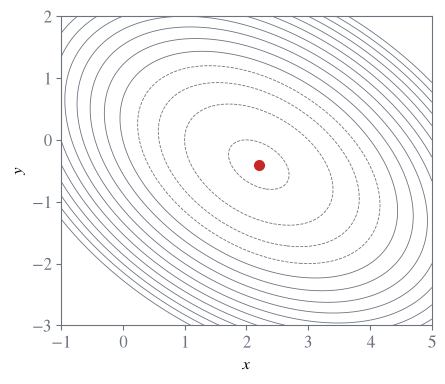

In [12]:
a, b, c, d, e = 2, 2, 3, -8, -2
xs, ys = np.meshgrid(np.linspace(-1, 5, 300), np.linspace(-3, 2, 300))
Z = a * xs ** 2 + b * xs * ys + c * ys ** 2 + d * xs + e * ys
fig, ax = plt.subplots(figsize=(5.4, 4))
ax.contour(xs, ys, Z, levels=np.linspace(-8, 20, 15), colors=HSE["gray"], linewidths=0.6)
ax.plot(2.2, -0.4, "o", color=HSE["accent"], ms=7)
ax.set(xlabel="$x$", ylabel="$y$", aspect="equal")
fig.tight_layout()
save(fig, "fig_a1")
plt.show()

### B1: gradient-descent path on the contour plot

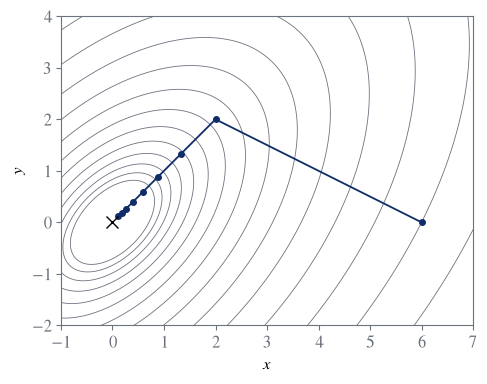

In [13]:
Q = np.array([[2.0, -1.0], [-1.0, 2.0]])
alpha = 1 / 3
x = np.array([6.0, 0.0])
path = [x.copy()]
for _ in range(8):
    x = x - alpha * Q @ x
    path.append(x.copy())
path = np.array(path)
xs, ys = np.meshgrid(np.linspace(-1, 7, 300), np.linspace(-2, 4, 300))
Z = xs ** 2 - xs * ys + ys ** 2
fig, ax = plt.subplots(figsize=(5.4, 4))
ax.contour(xs, ys, Z, levels=np.geomspace(0.5, 50, 15), colors=HSE["gray"], linewidths=0.6)
ax.plot(path[:, 0], path[:, 1], "o-", color=HSE["blue"], lw=1.3, ms=4)
ax.plot(0, 0, "x", color="black", ms=8)
ax.set(xlabel="$x$", ylabel="$y$", aspect="equal")
fig.tight_layout()
save(fig, "fig_b1")
plt.show()

### D1: three condition numbers

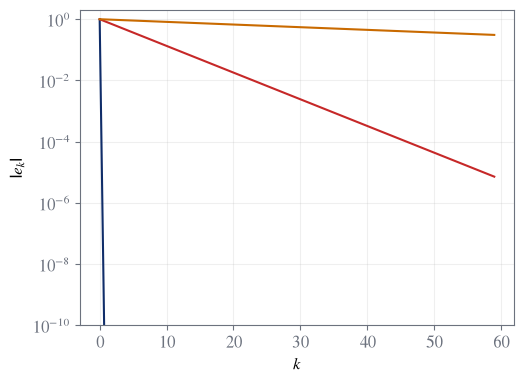

In [14]:
ks = [1, 10, 100]
colors = [HSE["blue"], HSE["accent"], HSE["orange"]]
fig, ax = plt.subplots(figsize=(5.4, 4))
for kappa, color in zip(ks, colors):
    r = (kappa - 1) / (kappa + 1)
    xs_ax = np.arange(60)
    if r == 0:
        ys_ax = np.ones_like(xs_ax, dtype=float)
        ys_ax[1:] = 1e-15
    else:
        ys_ax = r ** xs_ax
    ax.semilogy(xs_ax, np.maximum(ys_ax, 1e-15), color=color, lw=1.5)
ax.set(xlabel="$k$", ylabel=r"$|e_k|$", ylim=(1e-10, 2))
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "fig_kappa")
plt.show()

### D2: three step sizes, around the border

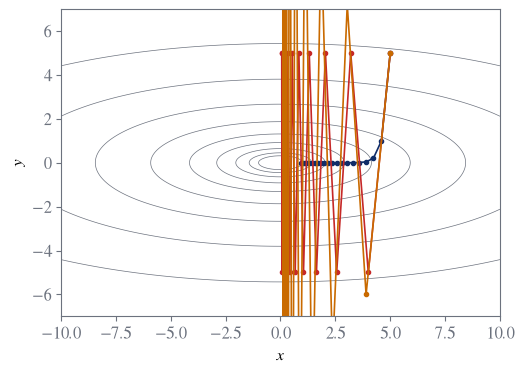

In [15]:
Q = np.array([[1.0, 0.0], [0.0, 10.0]])  # L = 10, mu = 1
x0 = np.array([5.0, 5.0])
alphas = [0.08, 0.2, 0.22]
colors = [HSE["blue"], HSE["accent"], HSE["orange"]]
fig, ax = plt.subplots(figsize=(5.4, 4))
u, v = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-7, 7, 300))
ax.contour(u, v, 0.5 * (u ** 2 + 10 * v ** 2), levels=np.geomspace(0.5, 300, 10), colors=HSE["gray"], linewidths=0.5)
for alpha, color in zip(alphas, colors):
    xs_p = [x0.copy()]
    for _ in range(20):
        nxt = xs_p[-1] - alpha * Q @ xs_p[-1]
        if np.linalg.norm(nxt) > 100:
            break
        xs_p.append(nxt)
    xs_p = np.array(xs_p)
    ax.plot(xs_p[:, 0], xs_p[:, 1], "o-", color=color, lw=1.2, ms=3)
ax.set(xlabel="$x$", ylabel="$y$", aspect="equal", xlim=(-10, 10), ylim=(-7, 7))
fig.tight_layout()
save(fig, "fig_border")
plt.show()

## 6. Content consistency

Both languages, tokens, figures, no stray numbers; the PDFs are newer than their sources.

In [16]:
# A simplified consistency pass: strict JSON, {en,ru} pairs, tokens resolve, every figure exists
CYR = re.compile("[Ѐ-ӿ]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = ["A1", "A2", "A3", "A4", "B1", "B2", "B3", "B4"]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Pp]robl\w* \d+(?:(?:, | and | to |–)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", "7"}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None


REQUIRE_RU = True
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-07", DOCS[name].get("id"), "seminar-07")

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])

pub_problems = public_content.get("problems", {})
check("consistency: the public problems are A1..A4, B1..B4", sorted(pub_problems), PROBLEM_IDS)
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems are A1, A3, B1, B3", sorted(board), ["A1", "A3", "B1", "B3"])

pub_figs = sorted({d["src"] for d in nodes(public_content) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (public_content, DOCS["students"].get("content", {}))
            for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure named exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/07/figures holds the public figures as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])

# PDFs: pages and overfull box
pdf_problems, pages = [], {}
for name in ("Theory_en", "Theory_ru", "Cheatsheet_en", "Cheatsheet_ru"):
    pdf = THEORY / f"{name}.pdf"
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    tex = THEORY / f"{name}.tex"
    log = THEORY / f"{name}.log"
    for fig in [FIG_DIR / f"{s}.pdf" for s in pub_figs]:
        if not fig.is_file():
            pdf_problems.append(f"{name}.pdf: {fig.name} missing")
        elif pdf.stat().st_mtime < fig.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {fig.name}")
    if tex.is_file() and pdf.stat().st_mtime < tex.stat().st_mtime - 2:
        pdf_problems.append(f"{name}.pdf older than {name}.tex")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources and the cheat sheets have one page", pdf_problems, [])

# web/07 hygiene (no fetch except access.js, no external URL, no Cyrillic outside the data file)
web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/07 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

35 of 35 consistency checks passed
strings: public: 193 strings, untranslated: 0; students: 82 strings, untranslated: 0; teacher: 9 strings, untranslated: 0
untranslated: 0
pages: Theory_en 7, Theory_ru 7, Cheatsheet_en 1, Cheatsheet_ru 1


## 7. Summary

In [17]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")

267 of 267 checks passed


## 8. Export

Only public numerical data are exported to the page.

In [18]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} -{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar07_data.js: unchanged (5333 bytes)
